# Praktikum Computer Vision – Transformasi Geometris Citra

**Nama :** (Muhamad Razzaaqi)  
**NIM  :** (G.211.24.0055)  
**Kelas :** (B2)

**Tujuan:** membuat fungsi transformasi geometris citra (translasi, rotasi, scaling, shearing, refleksi, affine, perspektif), lalu menerapkannya pada **20+ citra grayscale** dari folder dataset.

## 1. Landasan Teori Singkat

Translasi, rotasi, scaling, dan shearing dapat dinyatakan sebagai matriks affine 2×3 yang diterapkan dengan `cv2.warpAffine`:

| Transformasi | Ide |
|---|---|
| Translasi | menggeser citra sejauh (tx, ty) |
| Rotasi | memutar citra terhadap titik pusat |
| Scaling | memperbesar / memperkecil ukuran citra |
| Shearing | memiringkan citra searah sumbu x atau y |
| Refleksi | membalik citra horizontal / vertikal |
| Affine | transformasi dari 3 pasang titik; garis sejajar tetap sejajar |
| Perspektif | transformasi dari 4 pasang titik; garis sejajar bisa tidak sejajar lagi |

## 2. Import Library & Mount Drive

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### Cek isi folder dataset (diagnosis)

In [ ]:
import os
FOLDER_DIAG = "/content/drive/My Drive/Dataset_Serrano"
print("Folder ada? ", os.path.isdir(FOLDER_DIAG))
for akar, subfolder, berkas in os.walk(FOLDER_DIAG):
    print(f"{akar}  ->  {len(subfolder)} subfolder, {len(berkas)} file")
    print("   contoh file:", berkas[:5])
    break


Folder ada?  True
/content/drive/My Drive/Dataset_Serrano  ->  0 subfolder, 20 file
   contoh file: ['serrano (3)_01.tif', 'serrano (3)_02.tif', 'serrano (3)_03.tif', 'serrano (3)_04.tif', 'serrano (3)_05.tif']


## 3. Konfigurasi & Memuat Dataset (Grayscale)

Semua citra dibaca dari folder dataset, **dikonversi ke grayscale**, dan diseragamkan ukurannya agar perbandingan antar transformasi adil.

In [ ]:
FOLDER_DATASET = "/content/drive/My Drive/Dataset_Serrano"  # sesuaikan jika lokasi foldermu berbeda
FOLDER_OUTPUT  = "/content/hasil_transformasi"
UKURAN_SERAGAM = (256, 256)   # (lebar, tinggi)
MIN_CITRA      = 20


def muat_dataset(folder, ukuran, minimal):
    """Baca semua citra di folder (termasuk subfolder) -> grayscale -> ukuran seragam."""
    ekstensi = (".jpg", ".jpeg", ".jfif", ".png", ".bmp", ".tif", ".tiff", ".webp")

    # os.walk menelusuri folder utama dan seluruh subfolder
    jalur = []
    for akar, _, berkas in os.walk(folder):
        for f in berkas:
            if f.lower().endswith(ekstensi):
                jalur.append(os.path.join(akar, f))
    jalur.sort()

    daftar_citra, daftar_nama = [], []
    for p in jalur:
        abu = cv2.imread(p, cv2.IMREAD_GRAYSCALE)  # langsung grayscale
        if abu is None:
            print("Dilewati (gagal dibaca):", p)
            continue
        daftar_citra.append(cv2.resize(abu, ukuran, interpolation=cv2.INTER_AREA))
        # nama unik: gabungkan subfolder agar tidak saling menimpa saat disimpan
        daftar_nama.append(os.path.relpath(p, folder).replace(os.sep, "_"))

    assert len(daftar_citra) >= minimal, \
        f"Citra hanya {len(daftar_citra)}, minimal {minimal}. Cek isi folder (lihat cell diagnosis di atas)."
    return daftar_citra, daftar_nama


dataset, nama_berkas = muat_dataset(FOLDER_DATASET, UKURAN_SERAGAM, MIN_CITRA)
print(f"Jumlah citra dimuat : {len(dataset)}")
print(f"Ukuran tiap citra   : {dataset[0].shape}  (tinggi, lebar)")
print(f"Tipe data           : {dataset[0].dtype}")

Jumlah citra dimuat : 20
Ukuran tiap citra   : (256, 256)  (tinggi, lebar)
Tipe data           : uint8


## 4. Fungsi Transformasi Geometris

In [ ]:
# ---------- 1. TRANSLASI ----------
def translasi(citra, tx, ty):
    """Geser citra tx piksel ke kanan dan ty piksel ke bawah."""
    tinggi, lebar = citra.shape[:2]
    M = np.float32([[1, 0, tx],
                    [0, 1, ty]])
    return cv2.warpAffine(citra, M, (lebar, tinggi))


# ---------- 2. ROTASI ----------
def rotasi(citra, sudut, skala=1.0):
    """Putar citra sebesar 'sudut' derajat (berlawanan jarum jam) terhadap titik tengah.
    Matriks dibangun manual dari cos/sin agar terlihat asal-usul rumusnya."""
    tinggi, lebar = citra.shape[:2]
    cx, cy = lebar / 2.0, tinggi / 2.0
    rad = np.deg2rad(sudut)
    a = skala * np.cos(rad)
    b = skala * np.sin(rad)
    M = np.float32([[ a, b, (1 - a) * cx - b * cy],
                    [-b, a, b * cx + (1 - a) * cy]])
    return cv2.warpAffine(citra, M, (lebar, tinggi))


# ---------- 3. SCALING ----------
def scaling(citra, sx, sy):
    """Perbesar / perkecil citra. Interpolasi dipilih sesuai arah perubahan ukuran."""
    interpolasi = cv2.INTER_AREA if (sx < 1 or sy < 1) else cv2.INTER_CUBIC
    return cv2.resize(citra, None, fx=sx, fy=sy, interpolation=interpolasi)


# ---------- 4. SHEARING ----------
def shearing(citra, shx=0.0, shy=0.0):
    """Miringkan citra. shx: kemiringan horizontal (x' = x + shx*y),
    shy: kemiringan vertikal (y' = y + shy*x). Kanvas diperlebar agar tidak terpotong."""
    tinggi, lebar = citra.shape[:2]
    M = np.float32([[1,   shx, 0],
                    [shy, 1,   0]])
    if shx < 0:                      # geser balik supaya koordinat tidak negatif
        M[0, 2] = -shx * tinggi
    if shy < 0:
        M[1, 2] = -shy * lebar
    lebar_baru  = int(lebar  + abs(shx) * tinggi)
    tinggi_baru = int(tinggi + abs(shy) * lebar)
    return cv2.warpAffine(citra, M, (lebar_baru, tinggi_baru))


# ---------- 5. REFLEKSI ----------
def refleksi(citra, sumbu="horizontal"):
    """Cerminkan citra lewat pembalikan indeks array."""
    if sumbu == "horizontal":      # cermin kiri-kanan
        return citra[:, ::-1].copy()
    if sumbu == "vertikal":        # cermin atas-bawah
        return citra[::-1, :].copy()
    if sumbu == "keduanya":
        return citra[::-1, ::-1].copy()
    raise ValueError("sumbu harus 'horizontal', 'vertikal', atau 'keduanya'")


# ---------- 6. TRANSFORMASI AFFINE ----------
def transformasi_affine(citra, titik_asal=None, titik_tujuan=None):
    """Affine dari 3 pasang titik. Jika tidak diberi, dipakai titik relatif
    terhadap ukuran citra (jadi aman untuk citra ukuran berapa pun)."""
    tinggi, lebar = citra.shape[:2]
    if titik_asal is None:
        titik_asal = np.float32([[0, 0], [lebar - 1, 0], [0, tinggi - 1]])
    if titik_tujuan is None:
        titik_tujuan = np.float32([[0.10 * lebar, 0.15 * tinggi],
                                   [0.90 * lebar, 0.05 * tinggi],
                                   [0.25 * lebar, 0.85 * tinggi]])
    M = cv2.getAffineTransform(np.float32(titik_asal), np.float32(titik_tujuan))
    return cv2.warpAffine(citra, M, (lebar, tinggi))


# ---------- 7. TRANSFORMASI PERSPEKTIF ----------
def transformasi_perspektif(citra, titik_asal=None, titik_tujuan=None):
    """Perspektif (homografi) dari 4 pasang titik, juga memakai titik relatif."""
    tinggi, lebar = citra.shape[:2]
    if titik_asal is None:
        titik_asal = np.float32([[0, 0], [lebar - 1, 0],
                                 [lebar - 1, tinggi - 1], [0, tinggi - 1]])
    if titik_tujuan is None:
        titik_tujuan = np.float32([[0.20 * lebar, 0.10 * tinggi],
                                   [0.85 * lebar, 0.00 * tinggi],
                                   [lebar - 1,     tinggi - 1],
                                   [0.05 * lebar, 0.90 * tinggi]])
    M = cv2.getPerspectiveTransform(np.float32(titik_asal), np.float32(titik_tujuan))
    return cv2.warpPerspective(citra, M, (lebar, tinggi))

## 5. Fungsi Bantu: Tampilan Grid & Penyimpanan

In [ ]:
def tampilkan_grid(judul, daftar_citra, kolom=5, ukuran_sel=2.4):
    """Tampilkan semua hasil (satu transformasi untuk semua citra) dalam grid."""
    baris = int(np.ceil(len(daftar_citra) / kolom))
    fig, sumbu = plt.subplots(baris, kolom, figsize=(kolom * ukuran_sel, baris * ukuran_sel))
    for i, ax in enumerate(np.array(sumbu).ravel()):
        ax.axis("off")
        if i < len(daftar_citra):
            ax.imshow(daftar_citra[i], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"#{i + 1}", fontsize=8)
    fig.suptitle(judul, fontsize=13)
    plt.tight_layout()
    plt.show()


def simpan_hasil(nama_folder, daftar_citra, daftar_nama):
    folder = os.path.join(FOLDER_OUTPUT, nama_folder)
    os.makedirs(folder, exist_ok=True)
    for citra, nama in zip(daftar_citra, daftar_nama):
        cv2.imwrite(os.path.join(folder, nama), citra)

## 6. Menjalankan Semua Transformasi pada Seluruh Dataset

Parameter tiap transformasi dikumpulkan dalam satu dictionary supaya mudah diubah dan dibandingkan.

In [ ]:
DAFTAR_TRANSFORMASI = {
    "1_translasi":  ("Translasi (tx=40, ty=25)",          lambda g: translasi(g, 40, 25)),
    "2_rotasi":     ("Rotasi 30° berlawanan jarum jam",   lambda g: rotasi(g, 30)),
    "3_scaling":    ("Scaling 0.6x (pengecilan)",         lambda g: scaling(g, 0.6, 0.6)),
    "4_shearing":   ("Shearing horizontal (shx=0.3)",     lambda g: shearing(g, shx=0.3)),
    "5_refleksi":   ("Refleksi horizontal",               lambda g: refleksi(g, "horizontal")),
    "6_affine":     ("Transformasi Affine",               lambda g: transformasi_affine(g)),
    "7_perspektif": ("Transformasi Perspektif",           lambda g: transformasi_perspektif(g)),
}

hasil_semua = {}
for kunci, (keterangan, fungsi) in DAFTAR_TRANSFORMASI.items():
    hasil = [fungsi(g) for g in dataset]
    hasil_semua[kunci] = hasil
    simpan_hasil(kunci, hasil, nama_berkas)
    print(f"{keterangan:40s} -> {len(hasil)} citra tersimpan")

Translasi (tx=40, ty=25)                 -> 20 citra tersimpan
Rotasi 30° berlawanan jarum jam          -> 20 citra tersimpan
Scaling 0.6x (pengecilan)                -> 20 citra tersimpan
Shearing horizontal (shx=0.3)            -> 20 citra tersimpan
Refleksi horizontal                      -> 20 citra tersimpan
Transformasi Affine                      -> 20 citra tersimpan
Transformasi Perspektif                  -> 20 citra tersimpan


### 6.1 Citra Asli (Grayscale)

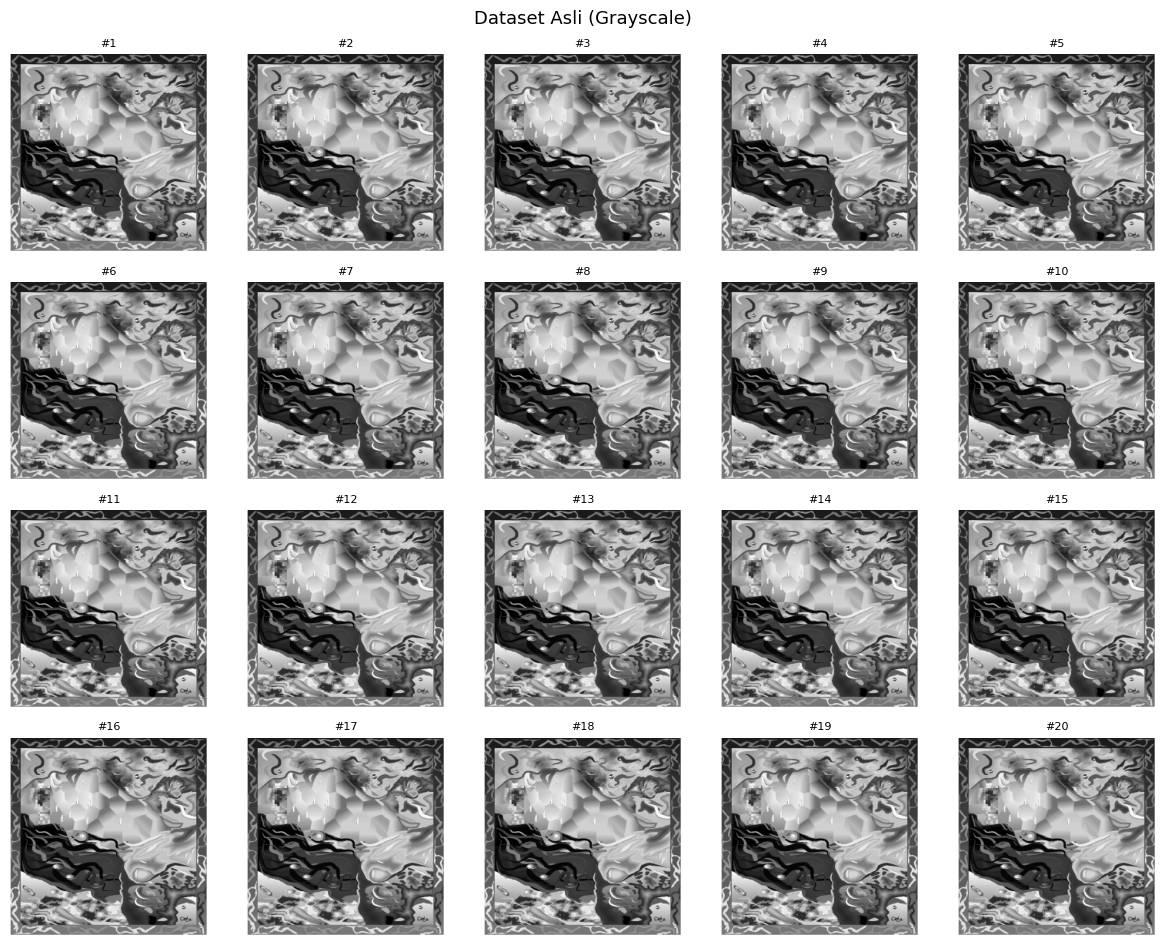

In [ ]:
tampilkan_grid("Dataset Asli (Grayscale)", dataset)

### 6.2 Hasil Tiap Transformasi

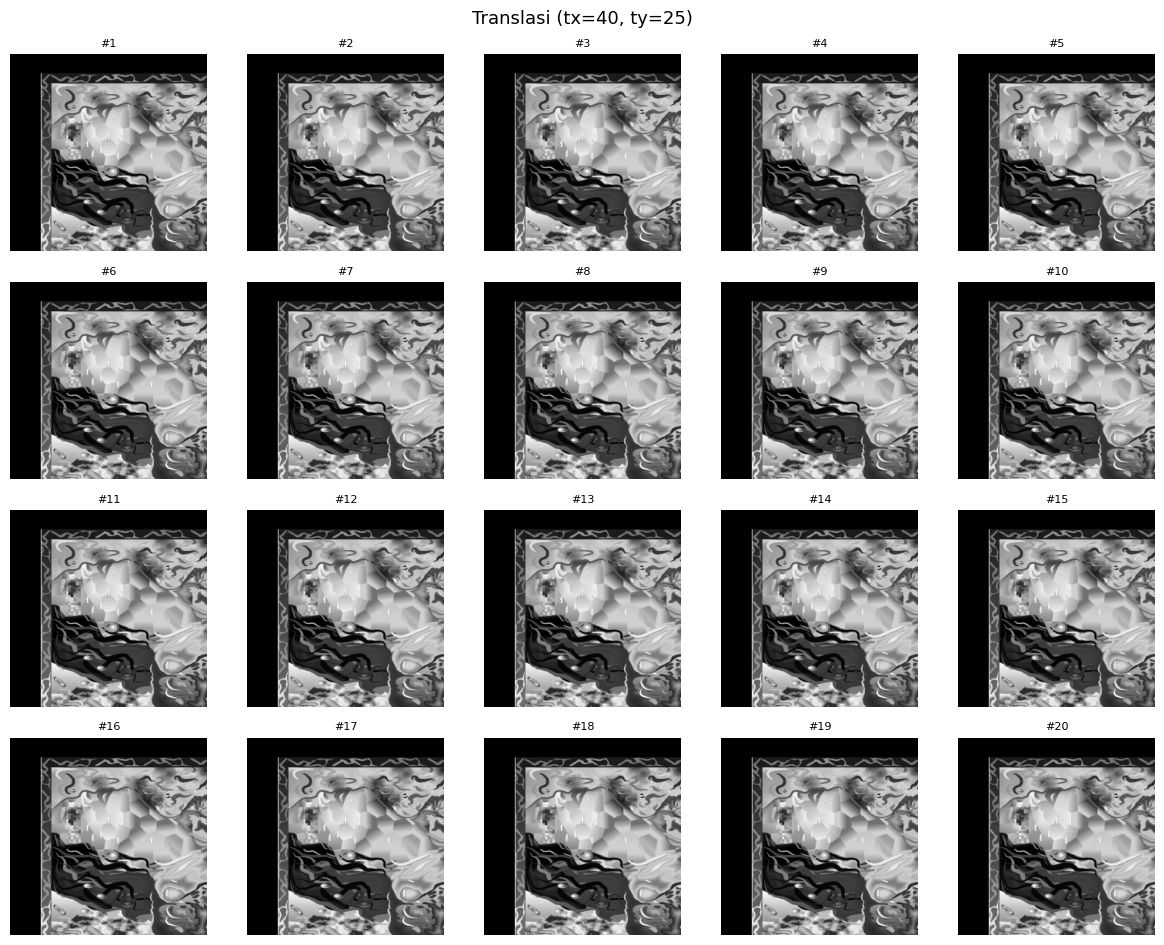

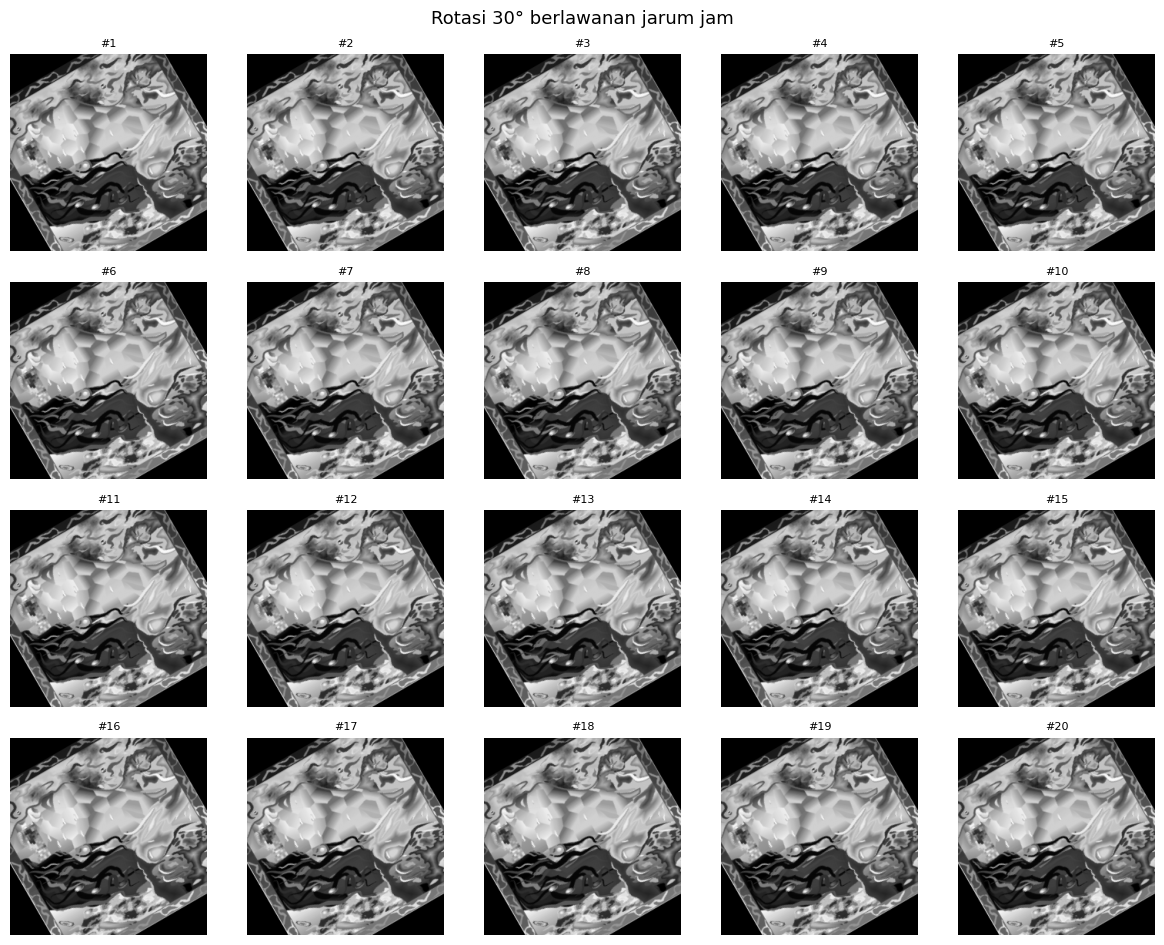

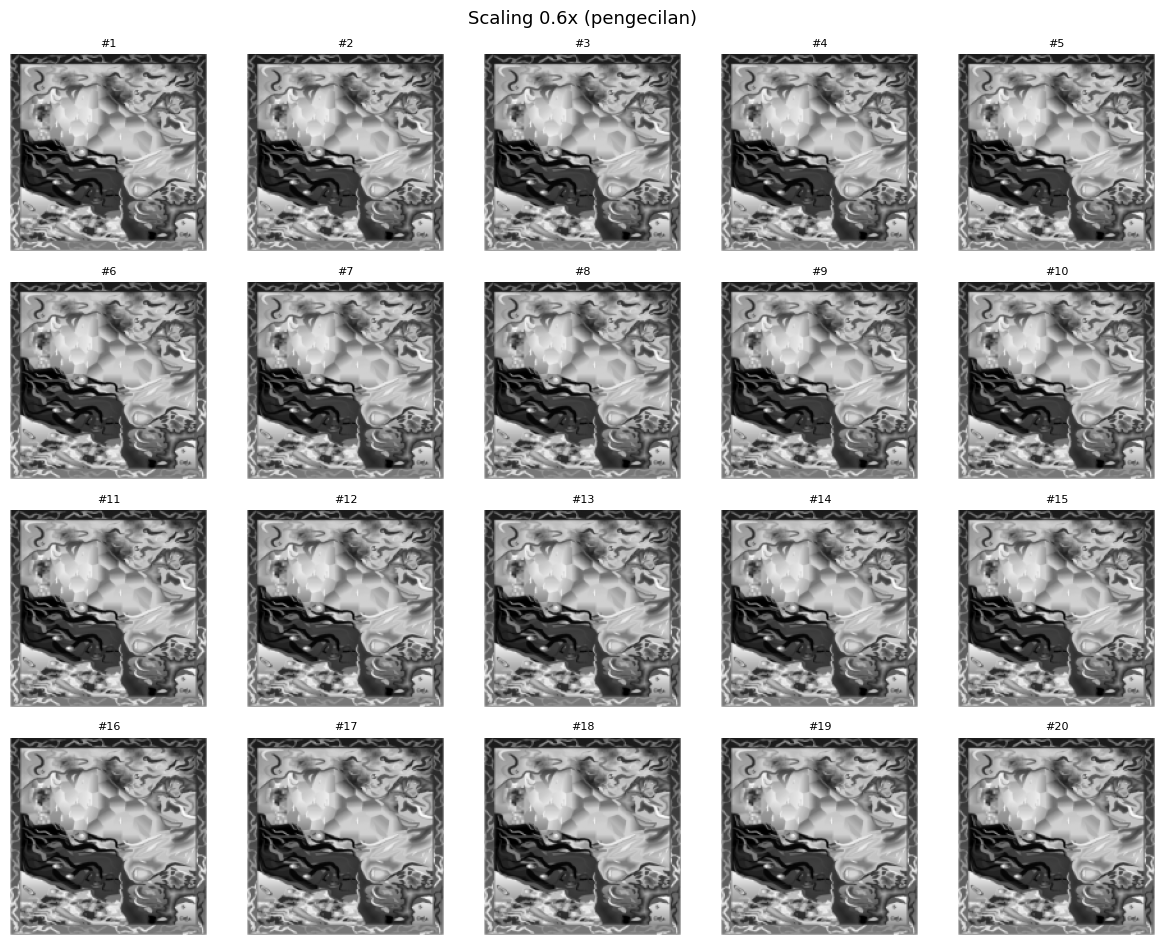

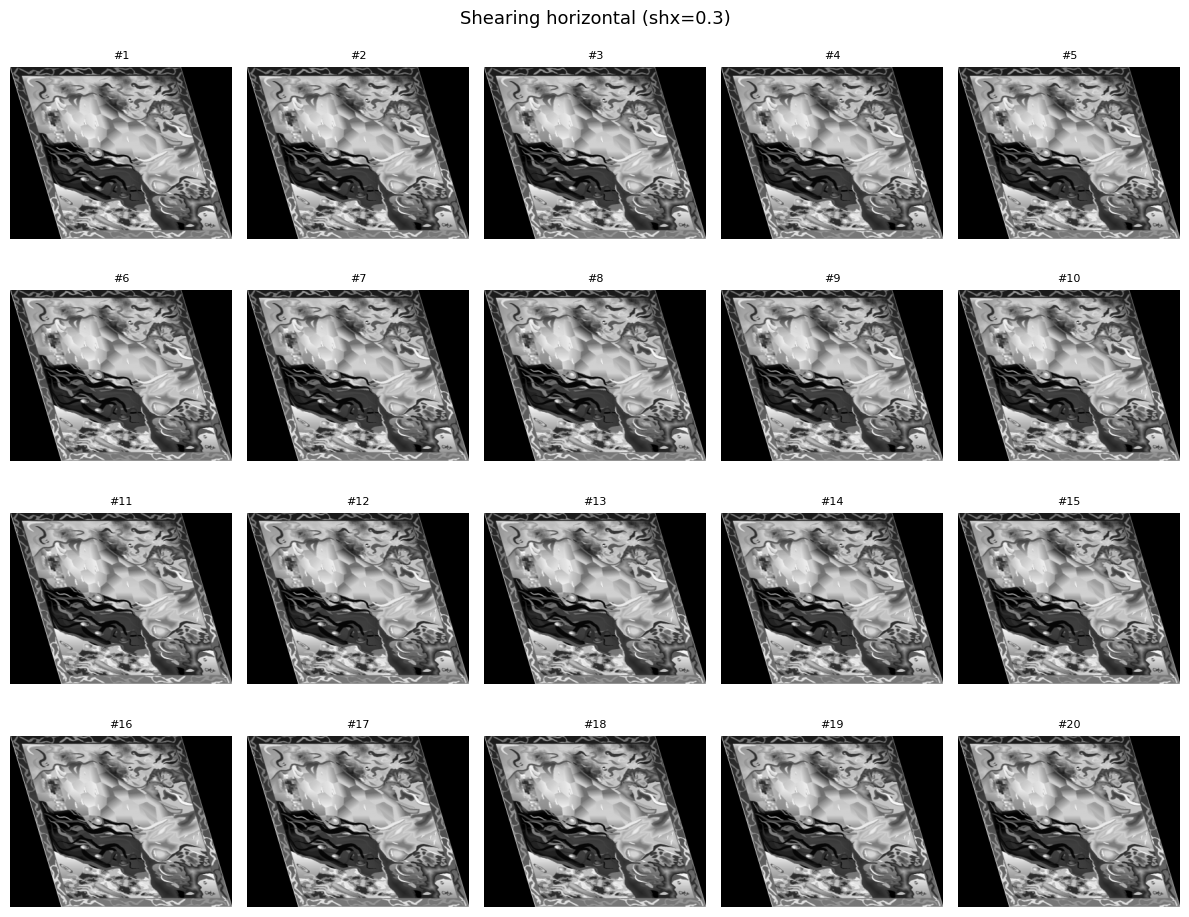

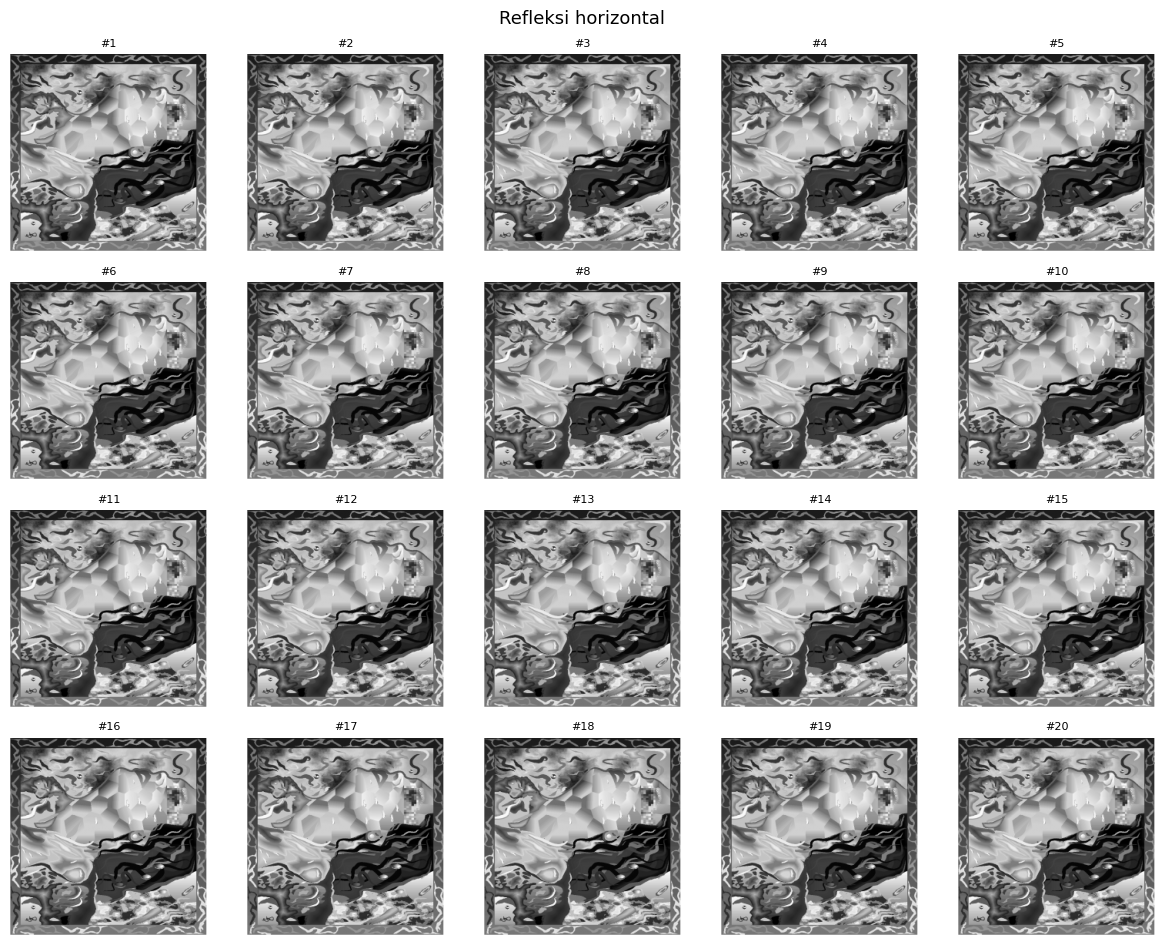

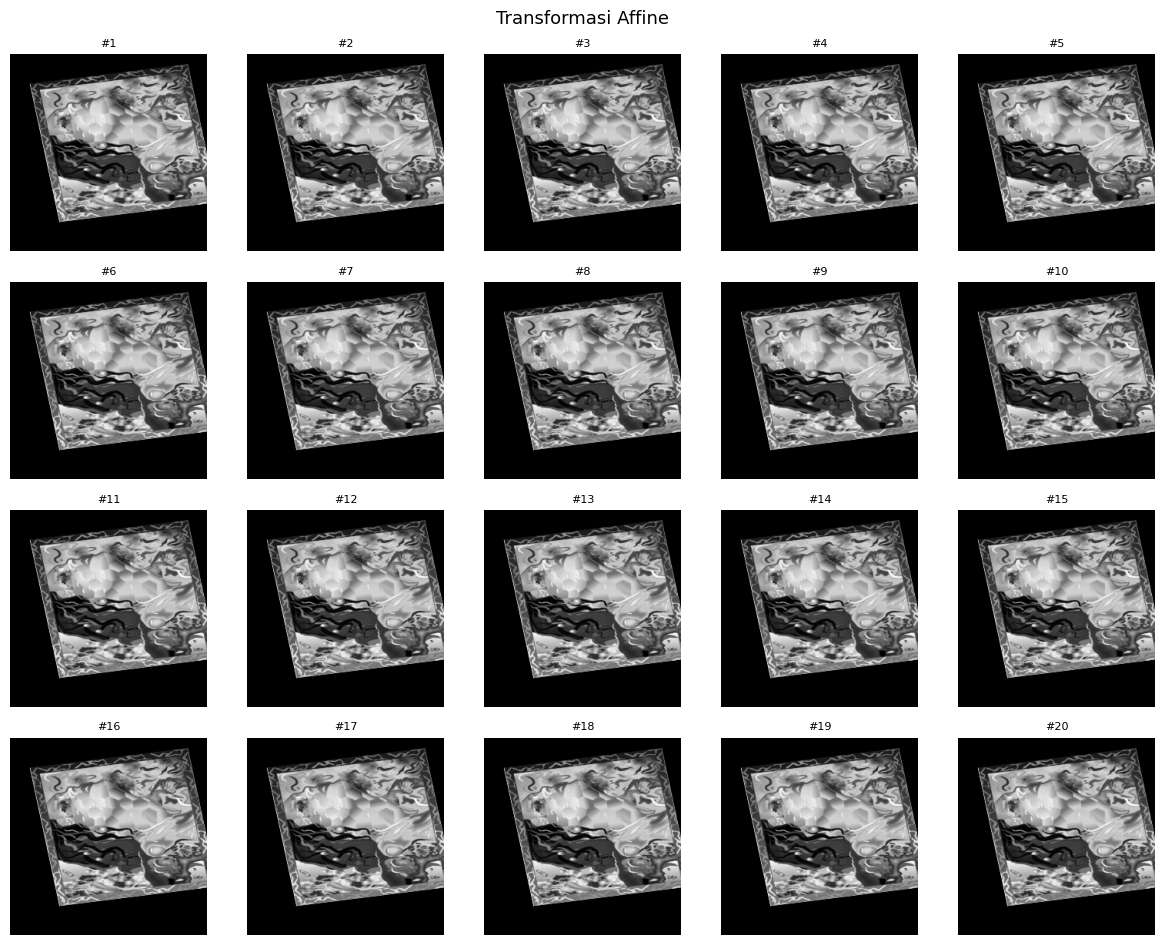

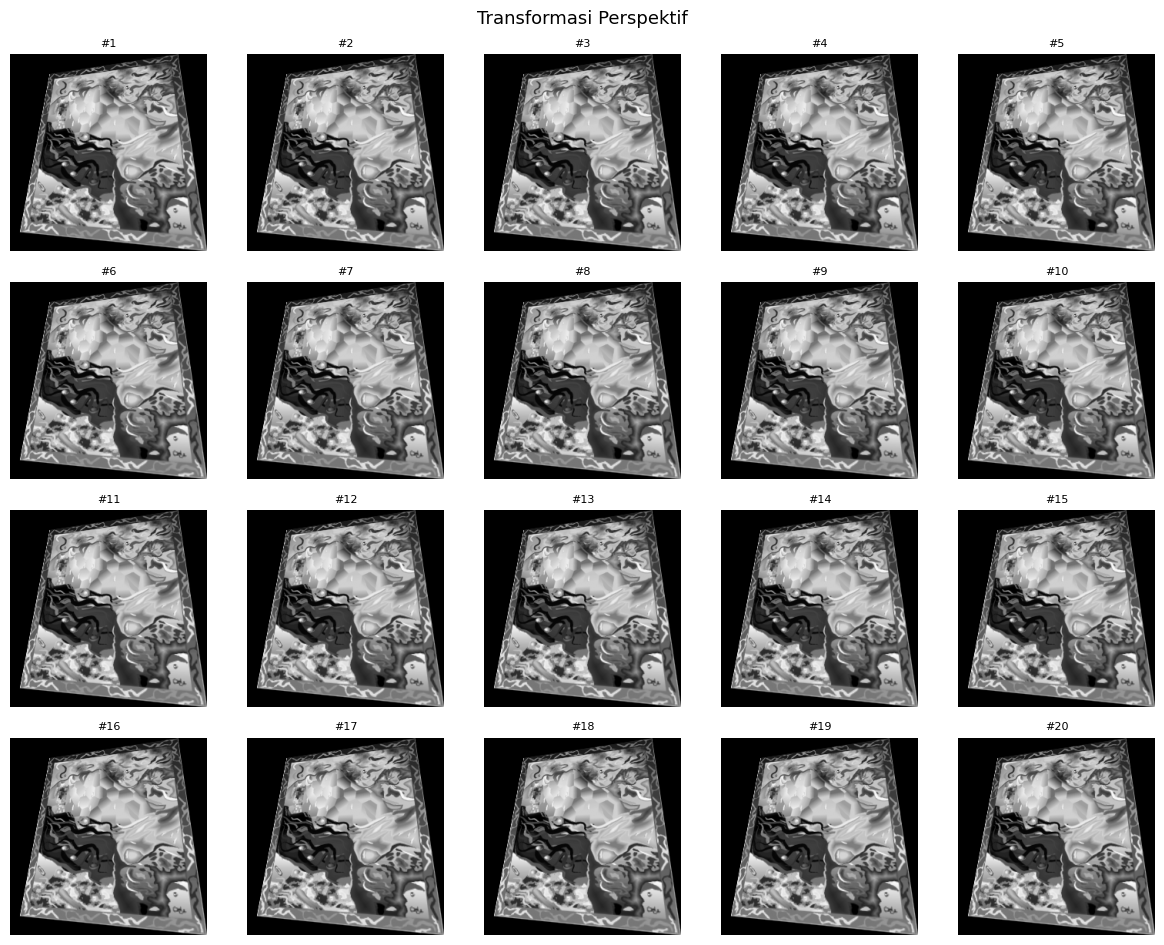

In [ ]:
for kunci, (keterangan, _) in DAFTAR_TRANSFORMASI.items():
    tampilkan_grid(keterangan, hasil_semua[kunci])

### 6.3 Perbandingan Seluruh Transformasi pada Satu Citra

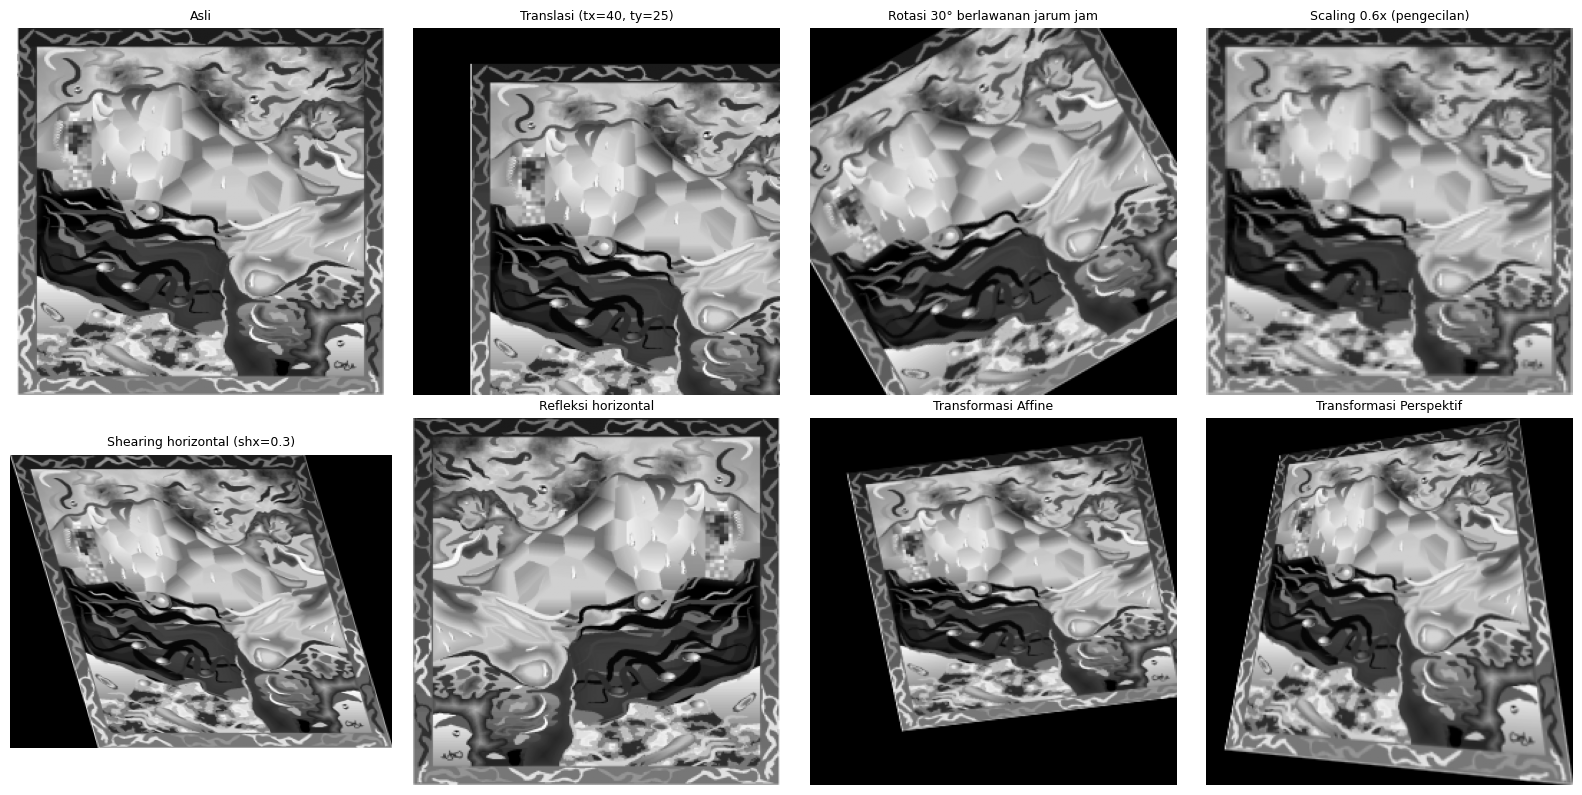

In [ ]:
indeks = 0   # ganti untuk melihat citra lain
judul = ["Asli"] + [v[0] for v in DAFTAR_TRANSFORMASI.values()]
gambar = [dataset[indeks]] + [hasil_semua[k][indeks] for k in DAFTAR_TRANSFORMASI]

fig, sumbu = plt.subplots(2, 4, figsize=(16, 8))
for ax, j, g in zip(sumbu.ravel(), judul, gambar):
    ax.imshow(g, cmap="gray", vmin=0, vmax=255)
    ax.set_title(j, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Kesimpulan:**

Pada praktikum ini telah dibuat tujuh fungsi transformasi geometris citra, yaitu translasi, rotasi, scaling, shearing, refleksi, affine, dan perspektif. Semuanya diterapkan pada dataset Dataset_Serrano (minimal 20 citra) yang sudah dikonversi ke grayscale.

Translasi, rotasi, scaling, dan shearing dapat dinyatakan dengan matriks affine 2×3. Transformasi ini dapat menimbulkan area hitam di tepi citra karena tidak ada piksel asal di posisi tersebut. Refleksi hanya membalik urutan piksel, sehingga paling sederhana dan tidak mengurangi kualitas citra. Transformasi affine memakai 3 pasang titik dan mempertahankan kesejajaran garis, sedangkan transformasi perspektif memakai 4 pasang titik dan menghasilkan efek perubahan sudut pandang.

Jadi, jenis transformasi dipilih sesuai kebutuhan: transformasi sederhana untuk mengubah posisi dan ukuran, serta affine dan perspektif untuk mengubah bentuk dan sudut pandang citra.